In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Лабораторная работа №2 
### Полиномиальная регрессия. Регуляризация. Кросс-валидация


1. Реализуйте программно восстановление функциональной зависимости методом наименьших квадратов с помощью полиномиальной регрессии. Для этого:
- а. используйте значения параметра M ∈ {0, 1, . . . , 15};
- б. генерируйте выборку двумя способами: в первом случае моделируйте ошибку измерения как равномерно распределённую случайную величину, во втором — как нормально распределённую случайную величину;
- в. генерируйте значения x из заданного интервала случайно в соответствии с равномерным распределением;
- г. в качестве распознаваемых функциональных зависимостей используйте следующие:
y=cos x, y=5x^3 + x^2 + 5, y=x sin x, x ∈ [0, 2π]

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
SEED = 42
rng = np.random.default_rng(SEED)

M_values = list(range(16))

N = 20
x_min, x_max = 0.0, 2 * np.pi
noise_level = 0.1

In [4]:
functions = {
    r"$y = \cos x$": np.cos,
    r"$y = 5x^3 + x^2 + 5$": lambda x: 5 * x**3 + x**2 + 5,
    r"$y = x \sin x$": lambda x: x * np.sin(x),
}

In [5]:
x_grid = np.linspace(x_min, x_max, 1000)
noise_types = ["u", "n"]


def generate_sample(f, noise_type="u") -> tuple:
    x = rng.uniform(x_min, x_max, N)  # выбокра

    f_grid = f(x_grid)
    sigma = noise_level * (f_grid.max() - f_grid.min())

    if noise_type == "u":
        a = sigma * np.sqrt(3)
        eps = rng.uniform(-a, a, N)
    else:
        eps = rng.normal(0, sigma, N)

    return x, f(x) + eps

In [6]:
# def design_matrix0(x, M):
#     return np.vander(x, M + 1, increasing=True)


def design_matrix(x, M):
    u = (x - (x_min + x_max) / 2) / ((x_max - x_min) / 2)
    return np.vander(u, M + 1, increasing=True)


def fit_polynomial(x, t, M):
    Phi = design_matrix(x, M)
    w, *_ = np.linalg.lstsq(Phi, t, rcond=None)
    return w


def predict(x, w):
    return design_matrix(x, len(w) - 1) @ w

In [7]:
results = {}  # ф-я, шум: выборка, веса и ошибки для всех M

for f_name, f in functions.items():
    for noise_type in noise_types:
        x, t = generate_sample(f, noise_type)
        f_true = f(x_grid)

        weights, train_err, true_err = [], [], []
        for M in M_values:
            w = fit_polynomial(x, t, M)
            weights.append(w)
            train_err.append(np.sqrt(np.mean((predict(x, w) - t) ** 2)))
            true_err.append(np.sqrt(np.mean((predict(x_grid, w) - f_true) ** 2)))

        results[(f_name, noise_type)] = {
            "x": x,
            "t": t,
            "weights": weights,
            "train_err": np.array(train_err),
            "true_err": np.array(true_err),
        }

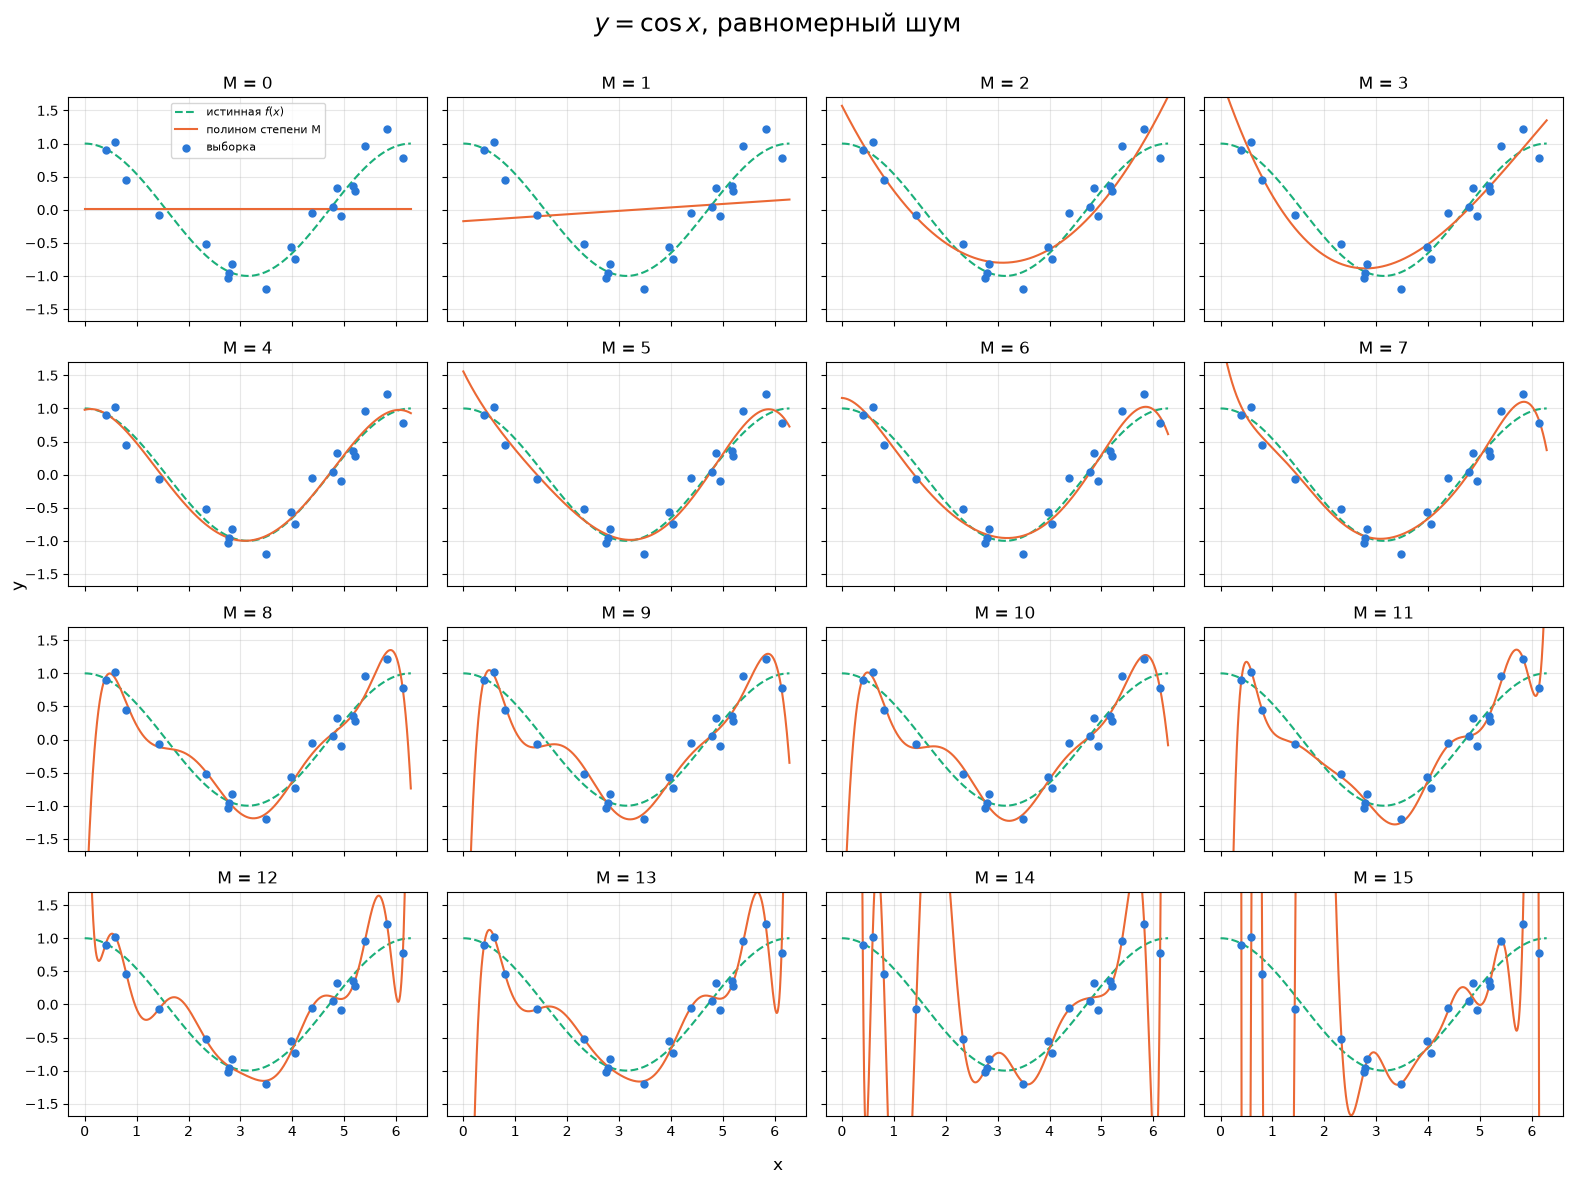

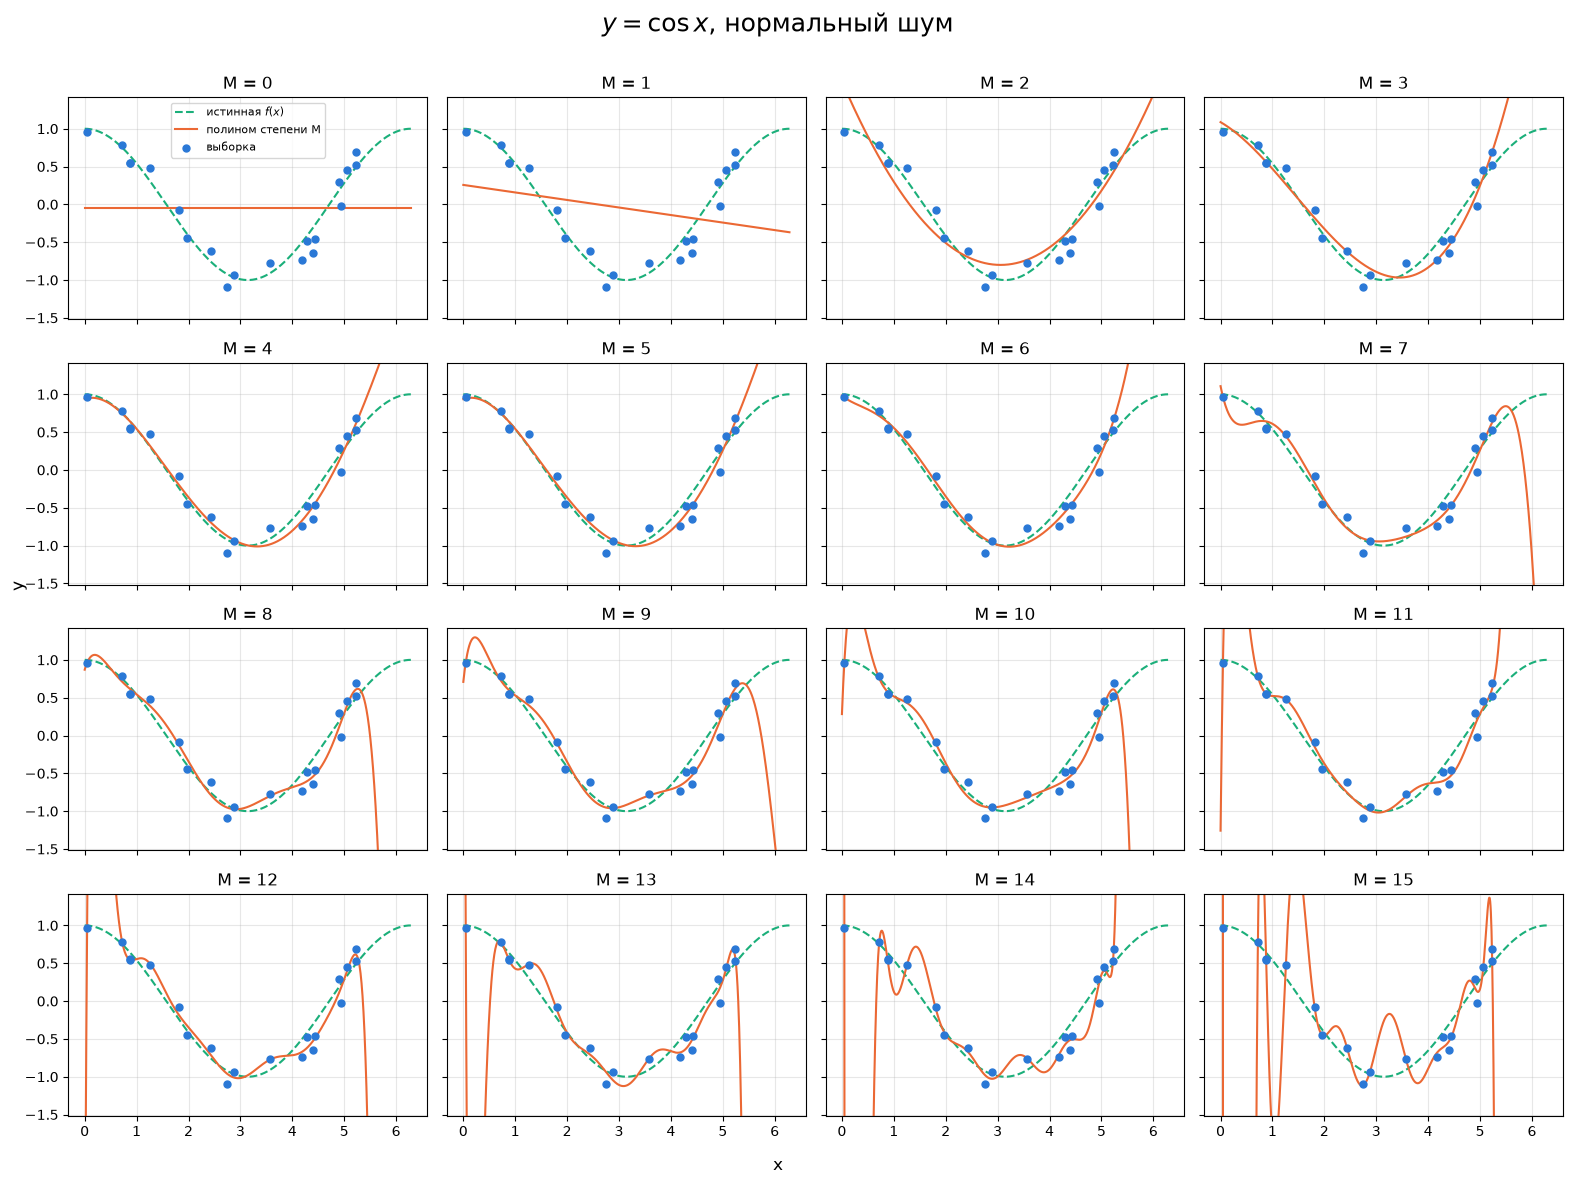

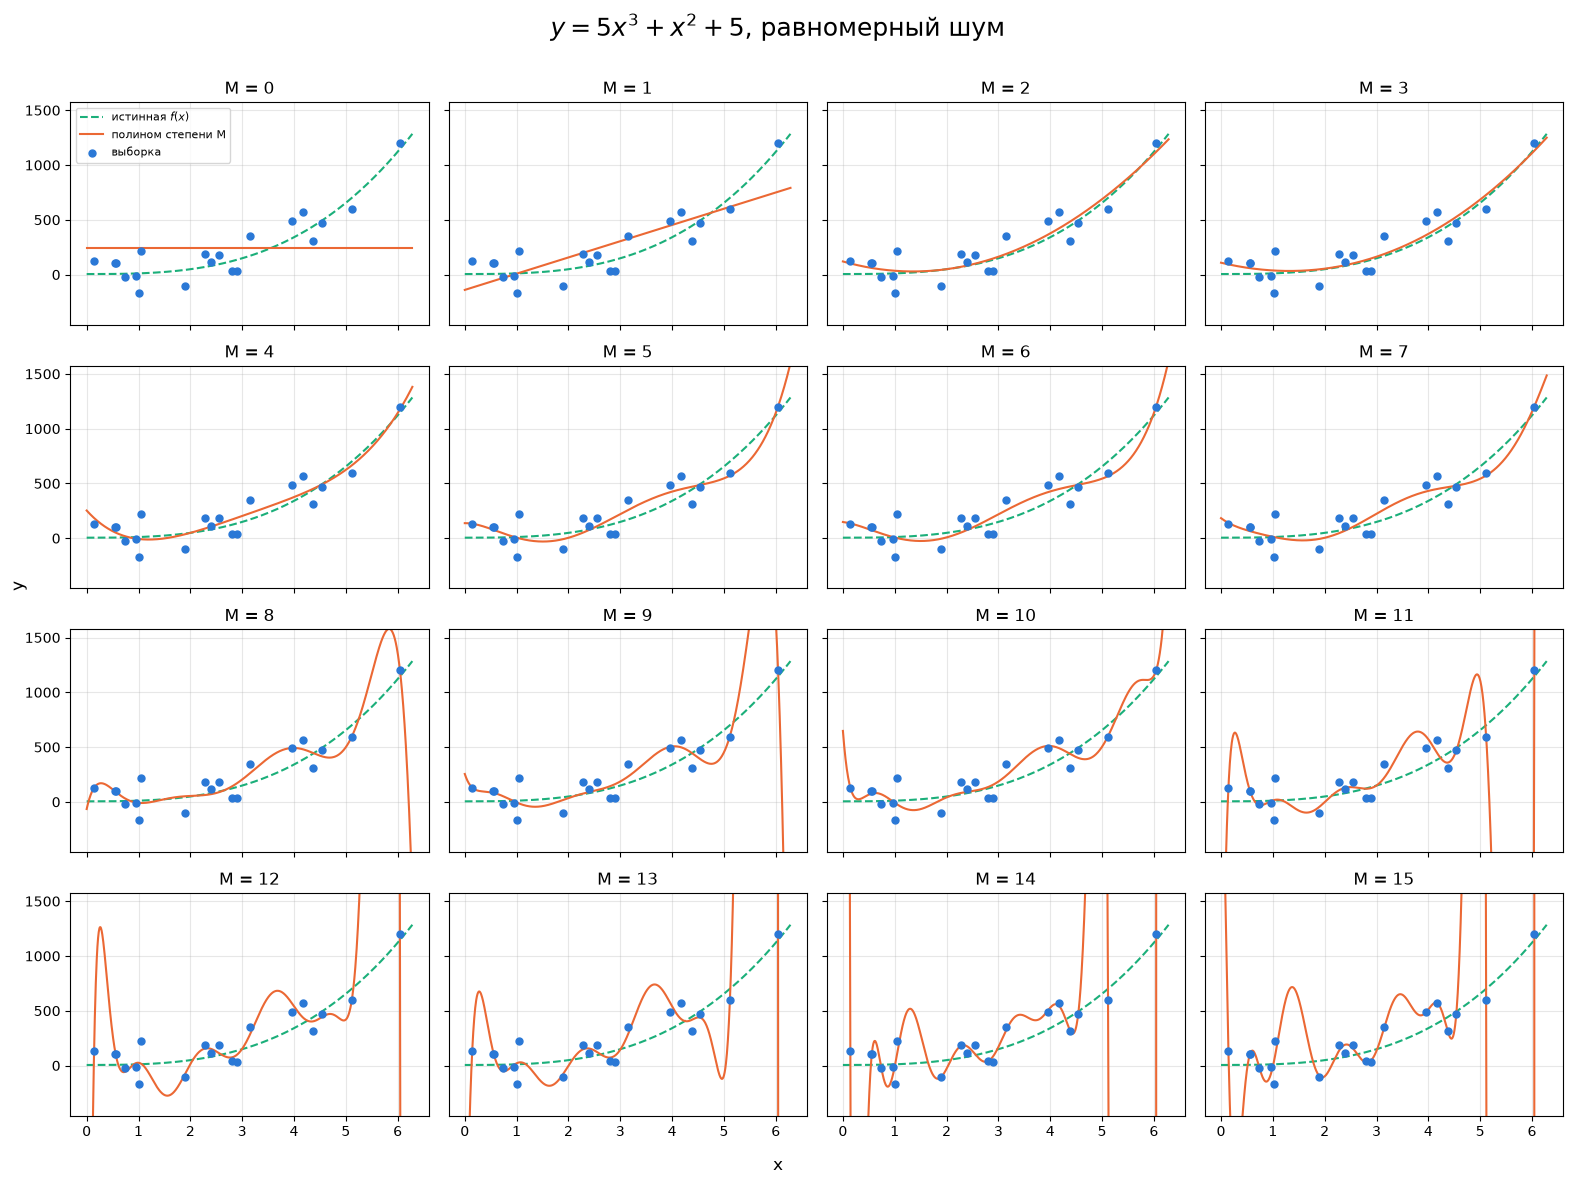

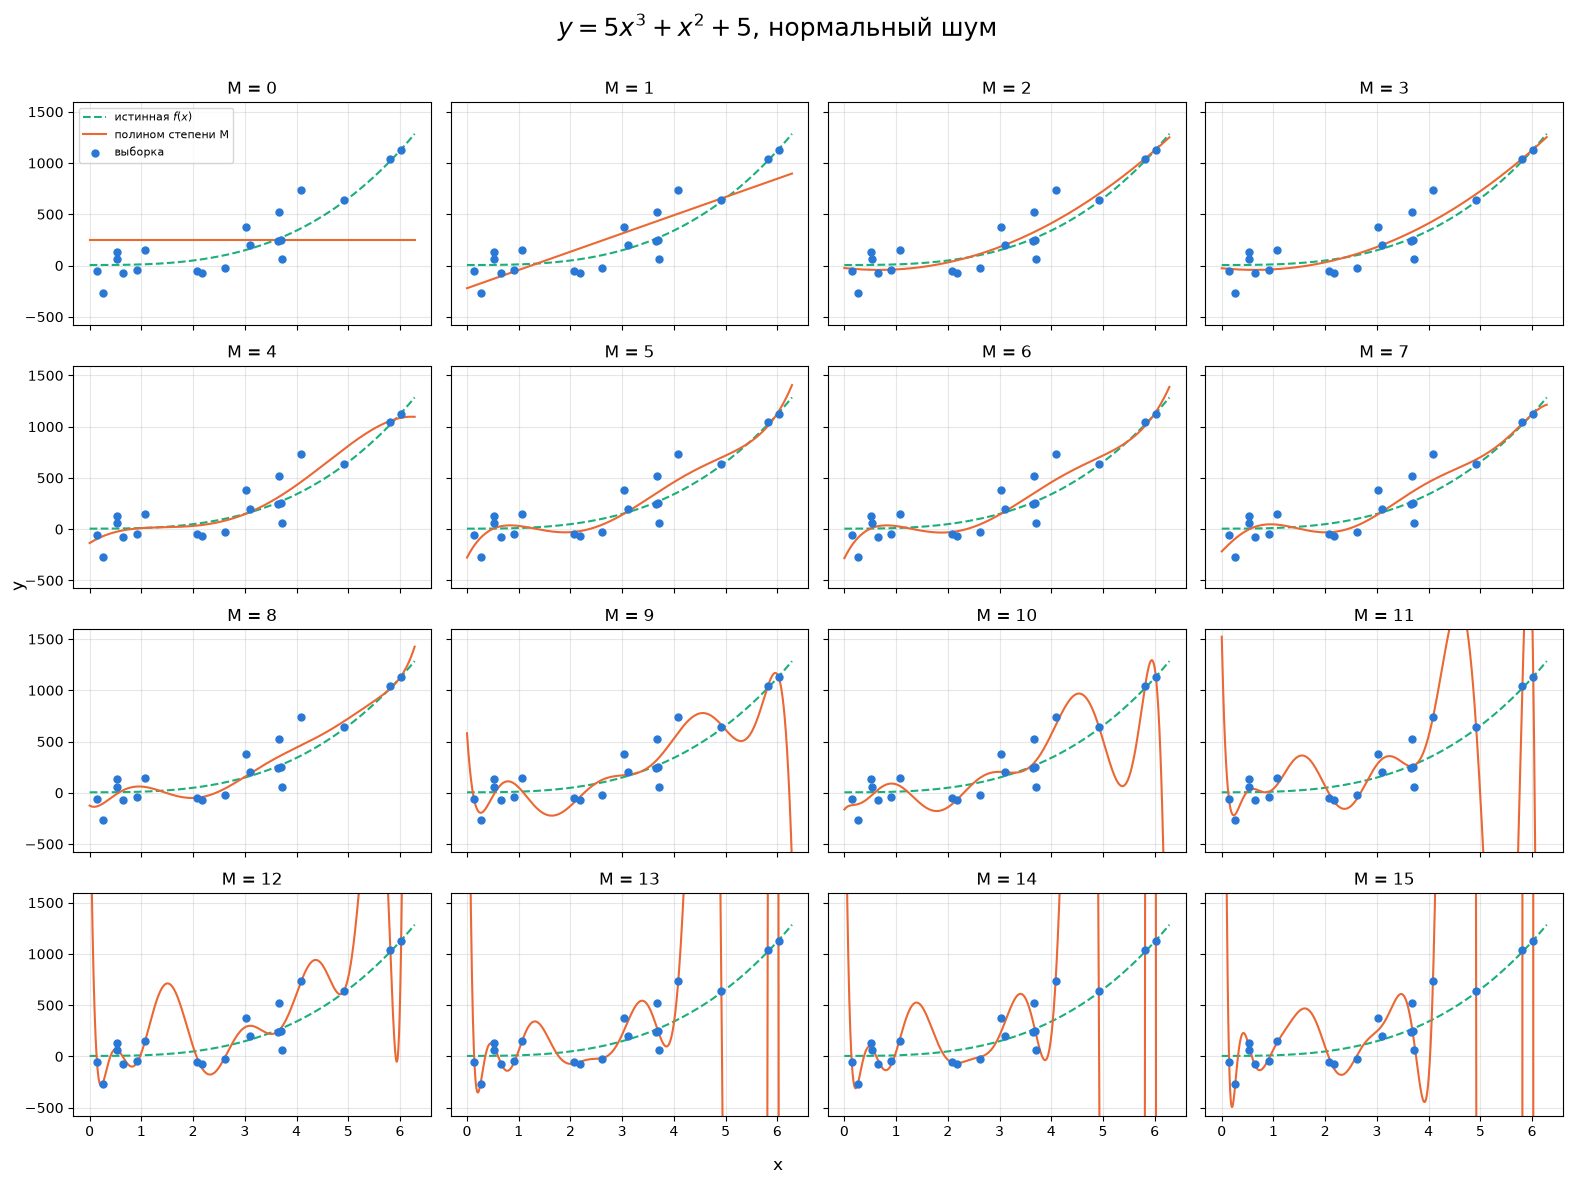

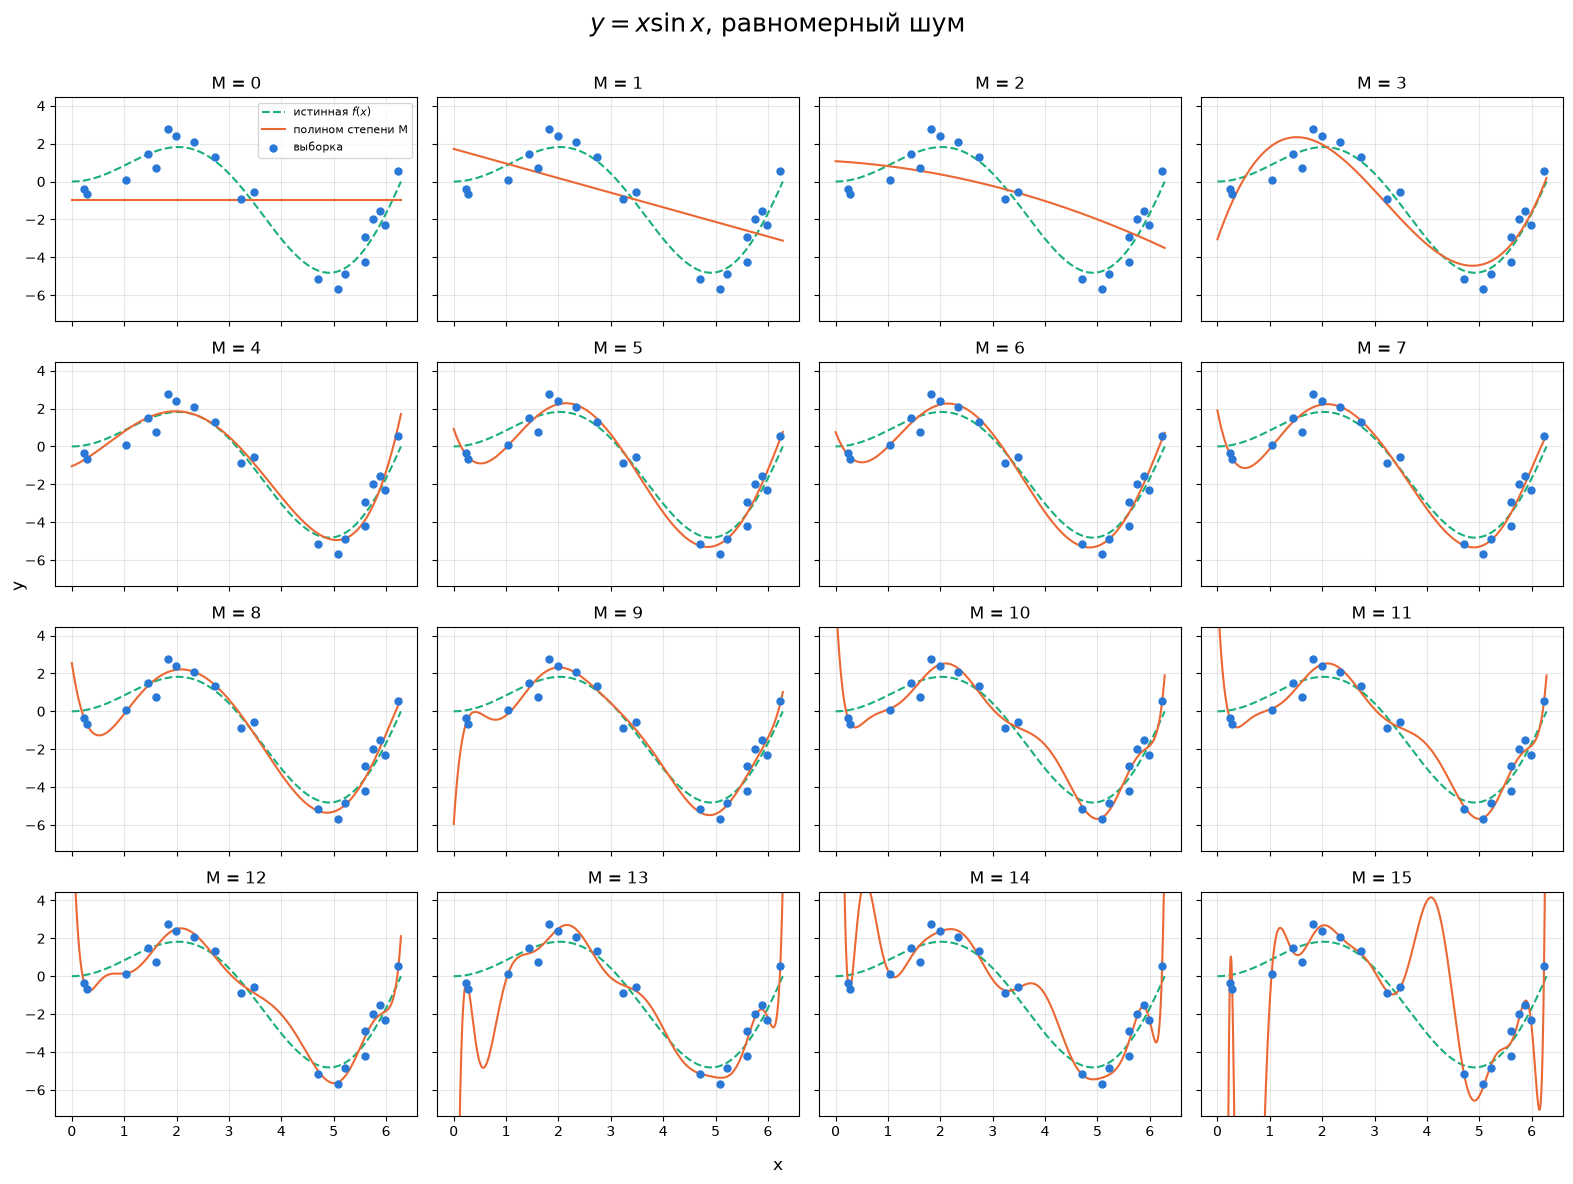

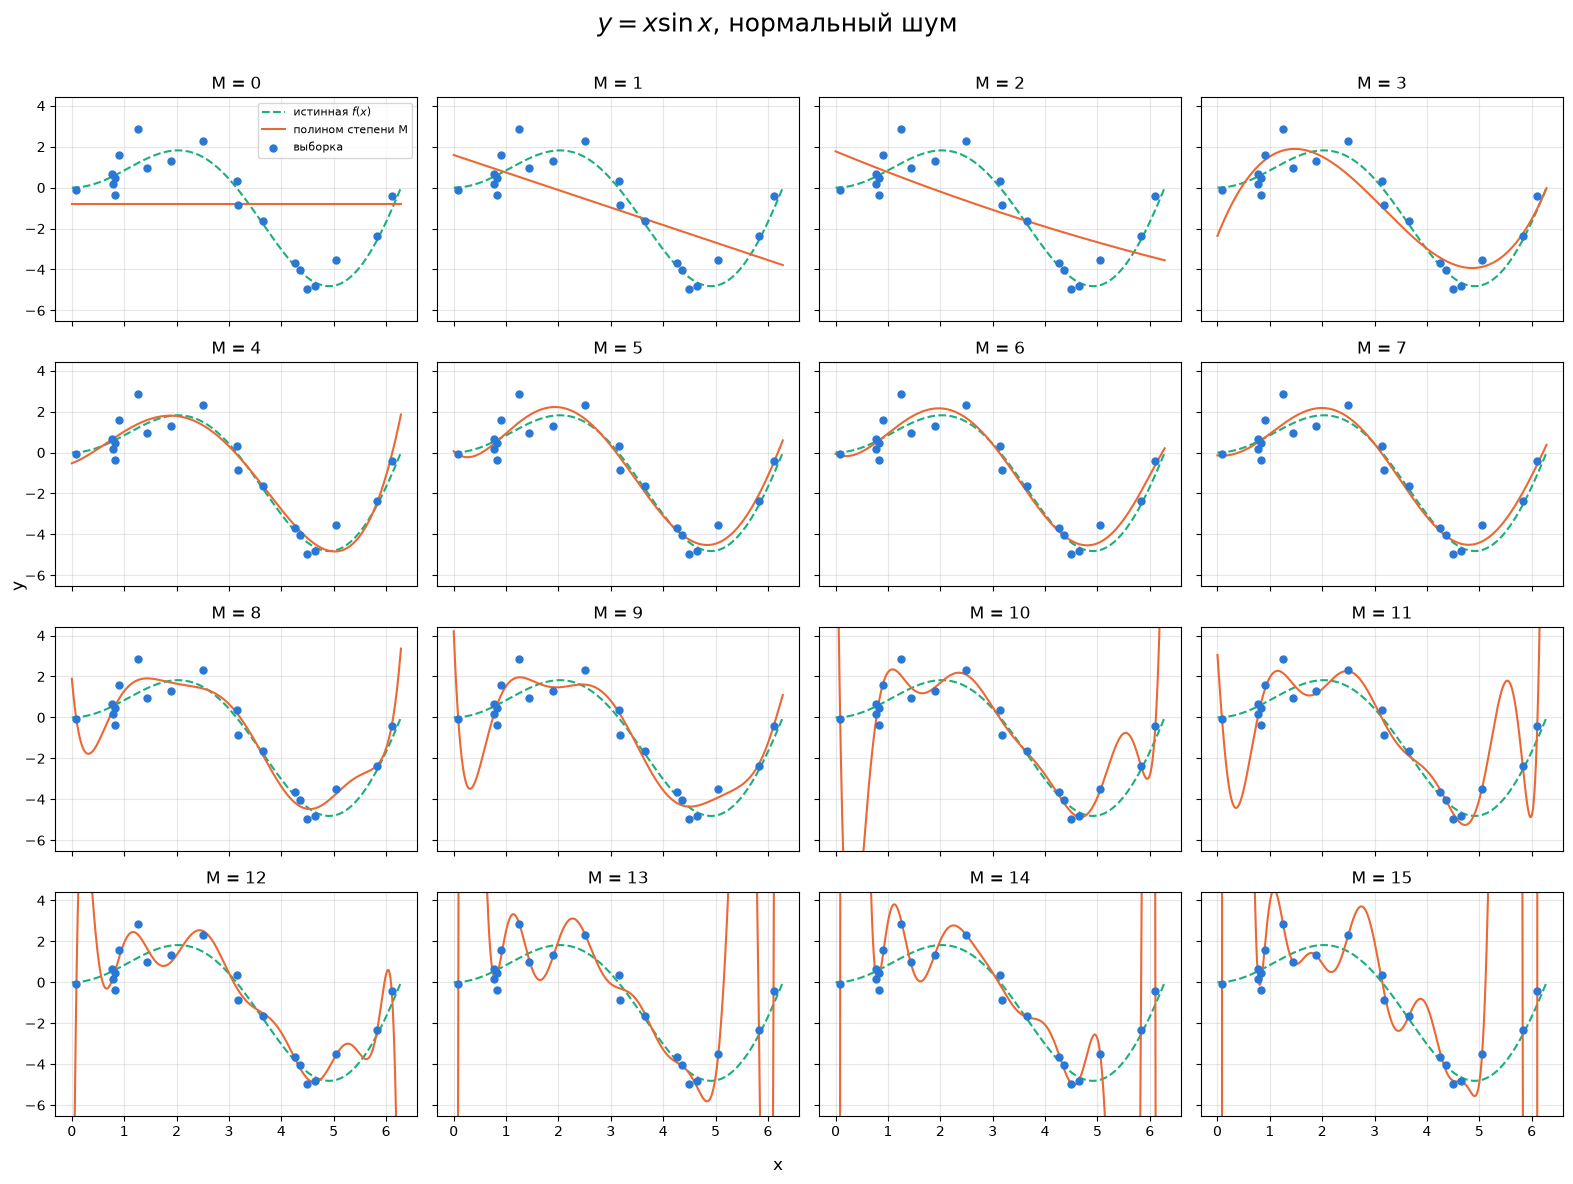

In [8]:
noise_names = {"u": "равномерный шум", "n": "нормальный шум"}

for (f_name, noise_type), res in results.items():
    x, t = res["x"], res["t"]
    f_true = functions[f_name](x_grid)

    # пределы по функции и выборке, с запасом 0.2
    y_lo, y_hi = min(f_true.min(), t.min()), max(f_true.max(), t.max())
    pad = 0.2 * (y_hi - y_lo)

    fig, axes = plt.subplots(4, 4, figsize=(16, 12), sharex=True, sharey=True)
    for M, ax in zip(M_values, axes.flat):
        ax.plot(x_grid, f_true, "--", color="#1baf7a", lw=1.5, label="истинная $f(x)$")
        ax.plot(
            x_grid,
            predict(x_grid, res["weights"][M]),
            "-",
            color="#eb6834",
            lw=1.5,
            label="полином степени M",
        )
        ax.scatter(x, t, s=25, color="#2a78d6", zorder=3, label="выборка")
        ax.set_title(f"M = {M}")
        ax.set_ylim(y_lo - pad, y_hi + pad)
        ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    fig.supxlabel("x")
    fig.supylabel("y")
    fig.suptitle(f"{f_name}, {noise_names[noise_type]}\n", fontsize=18)
    fig.tight_layout()
    plt.show()

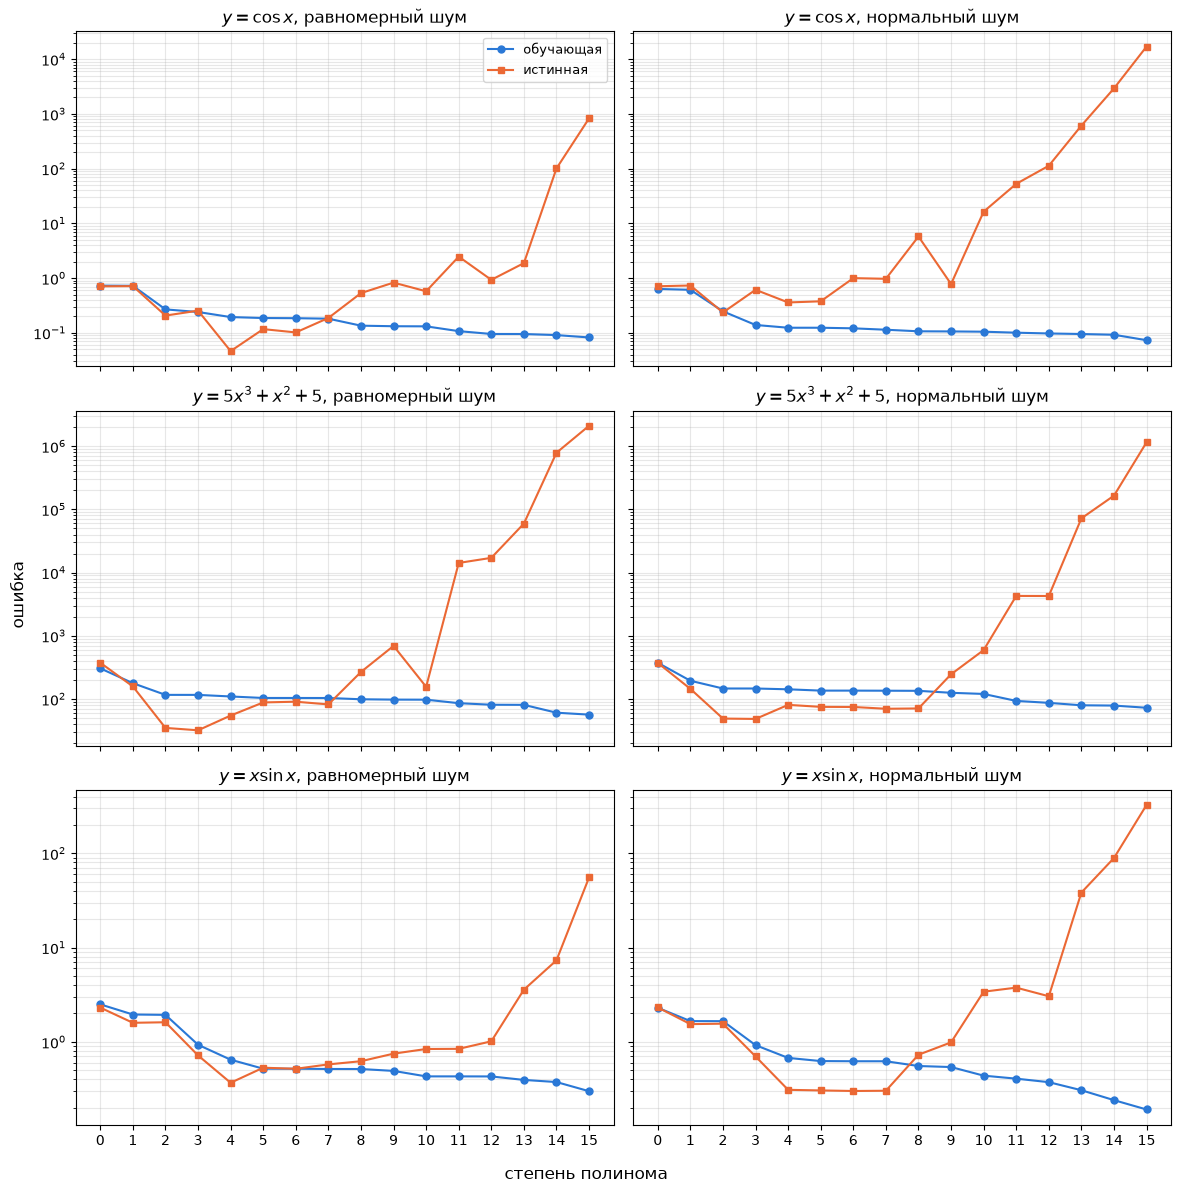

In [9]:
fig, axes = plt.subplots(
    len(functions), len(noise_types), figsize=(12, 12), sharex=True, sharey="row"
)

for i, f_name in enumerate(functions):
    for j, noise_type in enumerate(noise_types):
        res, ax = results[(f_name, noise_type)], axes[i, j]
        ax.plot(
            M_values,
            res["train_err"],
            "o-",
            color="#2a78d6",
            lw=1.5,
            ms=5,
            label="обучающая",
        )
        ax.plot(
            M_values,
            res["true_err"],
            "s-",
            color="#eb6834",
            lw=1.5,
            ms=5,
            label="истинная",
        )
        ax.set_yscale("log")
        ax.set_xticks(M_values)
        ax.set_title(f"{f_name}, {noise_names[noise_type]}")
        ax.grid(alpha=0.3, which="both")

axes[0, 0].legend(fontsize=9)
fig.supxlabel("степень полинома")
fig.supylabel("ошибка")
fig.tight_layout()
plt.show()

2. При условиях, сформулированных в задаче 1, реализуйте программно регуляризацию для полиномиальной регрессии и покажите, что переобучение может быть устранено при некоторых значениях M и λ. Найдите эти значения для выбранных функций и некоторых выборок, полученных для этих функций.

In [10]:
def fit_polynomial_reg(x, t, M, lam):  # L2
    Phi = design_matrix(x, M)
    A = np.vstack([Phi, np.sqrt(lam) * np.eye(M + 1)])
    b = np.concatenate([t, np.zeros(M + 1)])
    w, *_ = np.linalg.lstsq(A, b, rcond=None)
    return w

In [11]:
# λ = 0 (обычный МНК, задача 1) и 10^-12 ... 10^2 с шагом 10^0.5
lambdas = np.concatenate([[0.0], np.logspace(-12, 2, 29)])

reg_results = (
    {}
)  # (функция, тип шума) -> RMS-ошибка относительно f, матрица len(M_values) × len(lambdas)

for (f_name, noise_type), res in results.items():
    x, t = res["x"], res["t"]  # те же выборки, что в задаче 1
    f_true = functions[f_name](x_grid)

    true_err = np.zeros((len(M_values), len(lambdas)))
    for i, M in enumerate(M_values):
        for j, lam in enumerate(lambdas):
            w = fit_polynomial_reg(x, t, M, lam)
            true_err[i, j] = np.sqrt(np.mean((predict(x_grid, w) - f_true) ** 2))

    reg_results[(f_name, noise_type)] = true_err

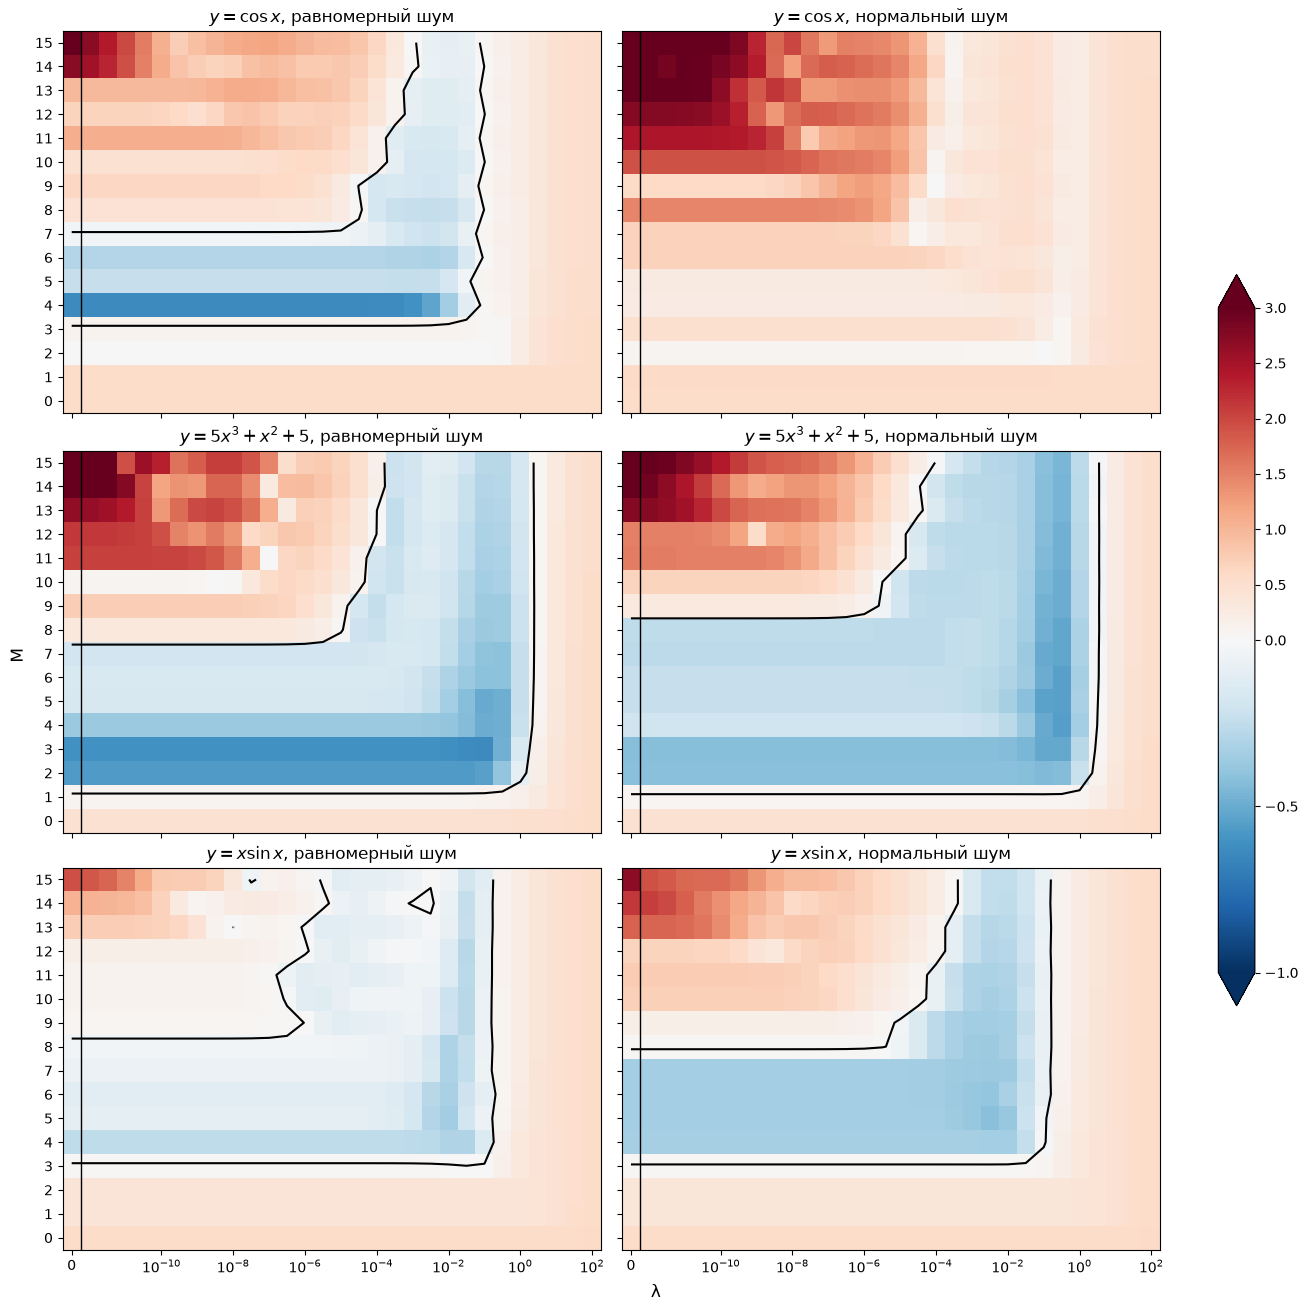

y = cos x, равномерный шум (σ = 0.2)
M =  8: E(λ=0) =     0.532  ->  E ≤ σ при λ ∈ [10^-4, 10^-1.5], лучшее λ = 10^-2.5 (E = 0.116)
M =  9: E(λ=0) =     0.827  ->  E ≤ σ при λ ∈ [10^-4.5, 10^-1.5], лучшее λ = 10^-2.5 (E = 0.129)
M = 10: E(λ=0) =     0.574  ->  E ≤ σ при λ ∈ [10^-3.5, 10^-1], лучшее λ = 10^-2.5 (E = 0.134)
M = 11: E(λ=0) =      2.47  ->  E ≤ σ при λ ∈ [10^-3.5, 10^-1.5], лучшее λ = 10^-2.5 (E = 0.138)
M = 12: E(λ=0) =     0.929  ->  E ≤ σ при λ ∈ [10^-3, 10^-1], лучшее λ = 10^-2 (E = 0.15)
M = 13: E(λ=0) =      1.88  ->  E ≤ σ при λ ∈ [10^-3, 10^-1.5], лучшее λ = 10^-2.5 (E = 0.15)
M = 14: E(λ=0) =       101  ->  E ≤ σ при λ ∈ [10^-2.5, 10^-1.5], лучшее λ = 10^-1.5 (E = 0.165)
M = 15: E(λ=0) =       831  ->  E ≤ σ при λ ∈ [10^-2.5, 10^-1.5], лучшее λ = 10^-2 (E = 0.164)
y = cos x, нормальный шум (σ = 0.2)
нет пар M и λ, где переобучение устранено по критерию
y = 5x^3 + x^2 + 5, равномерный шум (σ = 128)
M =  8: E(λ=0) =       268  ->  E ≤ σ при λ ∈ [10^-4.5, 10^0], лучш

In [12]:
from matplotlib.colors import TwoSlopeNorm

sigmas = {
    f_name: noise_level * (f(x_grid).max() - f(x_grid).min())
    for f_name, f in functions.items()
}

tick_idx = [0] + list(range(5, len(lambdas), 4))
tick_lbl = ["0"] + [f"$10^{{{np.log10(lambdas[k]):.0f}}}$" for k in tick_idx[1:]]
norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=3)

fig, axes = plt.subplots(
    len(functions),
    len(noise_types),
    figsize=(13, 13),
    sharex=True,
    sharey=True,
    layout="constrained",
)
for i, f_name in enumerate(functions):
    for j, noise_type in enumerate(noise_types):
        ax = axes[i, j]
        Z = np.log10(reg_results[(f_name, noise_type)] / sigmas[f_name])
        im = ax.imshow(Z, origin="lower", aspect="auto", cmap="RdBu_r", norm=norm)
        ax.contour(Z, levels=[0], colors="black", linewidths=1.5)  # граница E = σ
        ax.axvline(0.5, color="black", lw=1)  # отделяем столбец
        ax.set_xticks(tick_idx, tick_lbl)
        ax.set_yticks(M_values)
        ax.set_title(f"{f_name}, {noise_names[noise_type]}")
fig.supxlabel("λ")
fig.supylabel("M")
fig.colorbar(
    im,
    ax=axes,
    extend="both",
    shrink=0.6,
)

plt.show()

# Найденные значения: M, где регуляризация устраняет переобучение, и интервал лямбда
lam_str = lambda lam: f"10^{np.log10(lam):g}"

for (f_name, noise_type), E in reg_results.items():
    sigma = sigmas[f_name]
    name = f_name.replace("$", "").replace("\\", "")
    print(f"{name}, {noise_names[noise_type]} (σ = {sigma:.3g})")
    found = False
    for M in M_values:
        if (
            E[M, 0] <= sigma
        ):  # без регуляризации критерий уже выполнен — устранять нечего
            continue
        k = 1 + np.argmin(E[M, 1:])
        if E[M, k] > sigma:  # регуляризация не помогает
            continue
        lo, hi = k, k
        while lo > 1 and E[M, lo - 1] <= sigma:
            lo -= 1
        while hi < len(lambdas) - 1 and E[M, hi + 1] <= sigma:
            hi += 1
        found = True
        print(
            f"M = {M:2d}: E(λ=0) = {E[M, 0]:9.3g}  ->  E ≤ σ при λ ∈ [{lam_str(lambdas[lo])}, "
            f"{lam_str(lambdas[hi])}], лучшее λ = {lam_str(lambdas[k])} (E = {E[M, k]:.3g})"
        )
    if not found:
        print("нет пар M и λ, где переобучение устранено по критерию")

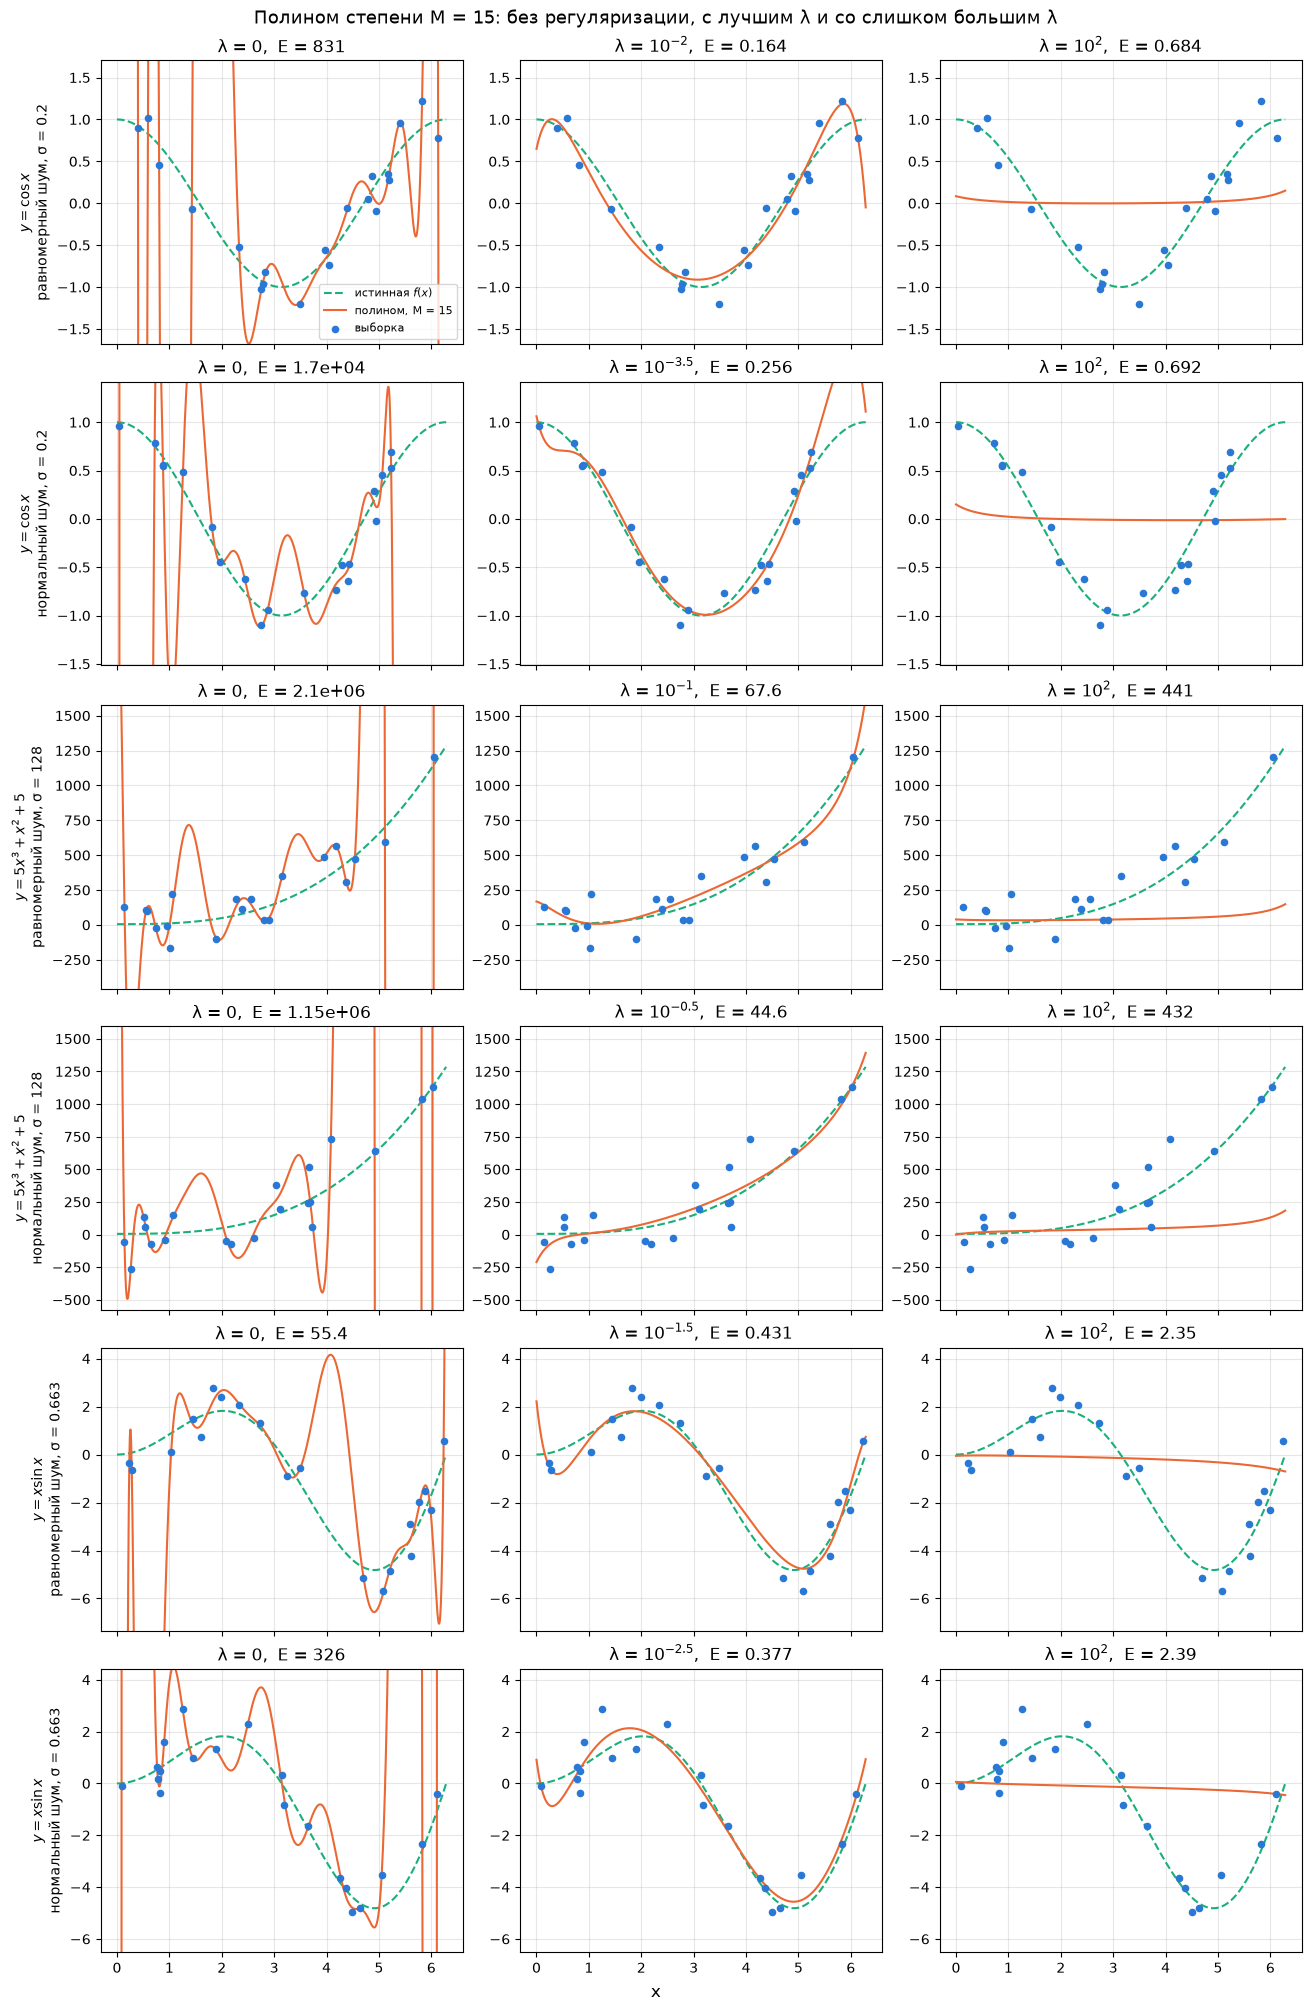

In [13]:
M_demo = 15  # самая переобученная степень

fig, axes = plt.subplots(
    len(results), 3, figsize=(13, 20), sharex=True, layout="constrained"
)
for row, ((f_name, noise_type), res) in zip(axes, results.items()):
    x, t = res["x"], res["t"]
    f_true = functions[f_name](x_grid)
    E = reg_results[(f_name, noise_type)][M_demo]  # ошибки M = 15 при всех л
    # три л: 0 (задача 1), лучшее л > 0 по сетке, наибольшее л сетки (10^2)
    k_show = [0, 1 + np.argmin(E[1:]), len(lambdas) - 1]

    y_lo, y_hi = min(f_true.min(), t.min()), max(f_true.max(), t.max())
    pad = 0.2 * (y_hi - y_lo)

    for ax, k in zip(row, k_show):
        w = fit_polynomial_reg(x, t, M_demo, lambdas[k])
        ax.plot(x_grid, f_true, "--", color="#1baf7a", lw=1.5, label="истинная $f(x)$")
        ax.plot(
            x_grid,
            predict(x_grid, w),
            "-",
            color="#eb6834",
            lw=1.5,
            label=f"полином, M = {M_demo}",
        )
        ax.scatter(x, t, s=20, color="#2a78d6", zorder=3, label="выборка")
        ax.set_ylim(y_lo - pad, y_hi + pad)
        lam_txt = "0" if k == 0 else f"$10^{{{np.log10(lambdas[k]):g}}}$"
        ax.set_title(f"λ = {lam_txt},  E = {E[k]:.3g}")
        ax.grid(alpha=0.3)
    row[0].set_ylabel(f"{f_name}\n{noise_names[noise_type]}, σ = {sigmas[f_name]:.3g}")

axes[0, 0].legend(fontsize=8)
fig.supxlabel("x")
fig.suptitle(
    f"Полином степени M = {M_demo}: без регуляризации, с лучшим λ и со слишком большим λ",
    fontsize=13,
)
plt.show()

3. Реализуйте программно кросс-валидацию для полиномиальной регрессии с регуляризацией. Определите наилучшую пару (M, λ) для восстановления функциональных зависимостей из задания 2.

In [14]:
def loo_cv_error(x, t, M, lam):
    N = len(x)
    residuals = np.empty(N)
    for i in range(N):
        mask = np.arange(N) != i  # все точки, кроме i-й
        w = fit_polynomial_reg(x[mask], t[mask], M, lam)
        residuals[i] = predict(x[i : i + 1], w)[0] - t[i]  # ошибка на исключённой точке
    return np.sqrt(np.mean(residuals**2))

In [15]:
cv_results = {}
best_pairs = {}

for (f_name, noise_type), res in results.items():
    x, t = res["x"], res["t"]  # те же выборки, что в задачах 1 и 2
    cv_err = np.zeros((len(M_values), len(lambdas)))
    for i, M in enumerate(M_values):
        for j, lam in enumerate(lambdas):
            cv_err[i, j] = loo_cv_error(x, t, M, lam)
    cv_results[(f_name, noise_type)] = cv_err

    i, j = np.unravel_index(np.argmin(cv_err), cv_err.shape)
    best_pairs[(f_name, noise_type)] = (M_values[i], lambdas[j])

lam_txt = lambda lam: "0" if lam == 0 else lam_str(lam)

for key, (M_cv, lam_cv) in best_pairs.items():
    f_name, noise_type = key
    E, cv_err, sigma = reg_results[key], cv_results[key], sigmas[f_name]
    i, j = M_values.index(M_cv), np.flatnonzero(lambdas == lam_cv)[0]
    io, jo = np.unravel_index(np.argmin(E), E.shape)  # наилучшая пара по истинной f

    name = f_name.replace("$", "").replace("\\", "")
    print(f"{name}, {noise_names[noise_type]} (σ = {sigma:.3g})")
    print(
        f"кросс-валидация: M = {M_cv:2d}, λ = {lam_txt(lam_cv):9s} LOO = {cv_err[i, j]:.3g}"
        f'->  E = {E[i, j]:.3g} ({"≤" if E[i, j] <= sigma else ">"} σ)'
    )
    print(
        f"по истинной f: M = {M_values[io]:2d}, λ = {lam_txt(lambdas[jo]):9s} E = {E[io, jo]:.3g}"
    )

y = cos x, равномерный шум (σ = 0.2)
кросс-валидация: M = 14, λ = 10^-2     LOO = 0.29->  E = 0.166 (≤ σ)
по истинной f: M =  4, λ = 0         E = 0.0463
y = cos x, нормальный шум (σ = 0.2)
кросс-валидация: M =  4, λ = 10^-3     LOO = 0.156->  E = 0.366 (> σ)
по истинной f: M =  9, λ = 10^-4     E = 0.205
y = 5x^3 + x^2 + 5, равномерный шум (σ = 128)
кросс-валидация: M =  5, λ = 10^-3.5   LOO = 131->  E = 85.9 (≤ σ)
по истинной f: M =  3, λ = 10^-1     E = 29.6
y = 5x^3 + x^2 + 5, нормальный шум (σ = 128)
кросс-валидация: M =  2, λ = 10^-1.5   LOO = 166->  E = 47.8 (≤ σ)
по истинной f: M =  4, λ = 10^-0.5   E = 36
y = x sin x, равномерный шум (σ = 0.663)
кросс-валидация: M =  5, λ = 10^-3     LOO = 0.677->  E = 0.446 (≤ σ)
по истинной f: M =  5, λ = 10^-2     E = 0.299
y = x sin x, нормальный шум (σ = 0.663)
кросс-валидация: M =  5, λ = 0         LOO = 0.845->  E = 0.305 (≤ σ)
по истинной f: M =  5, λ = 10^-2.5   E = 0.253


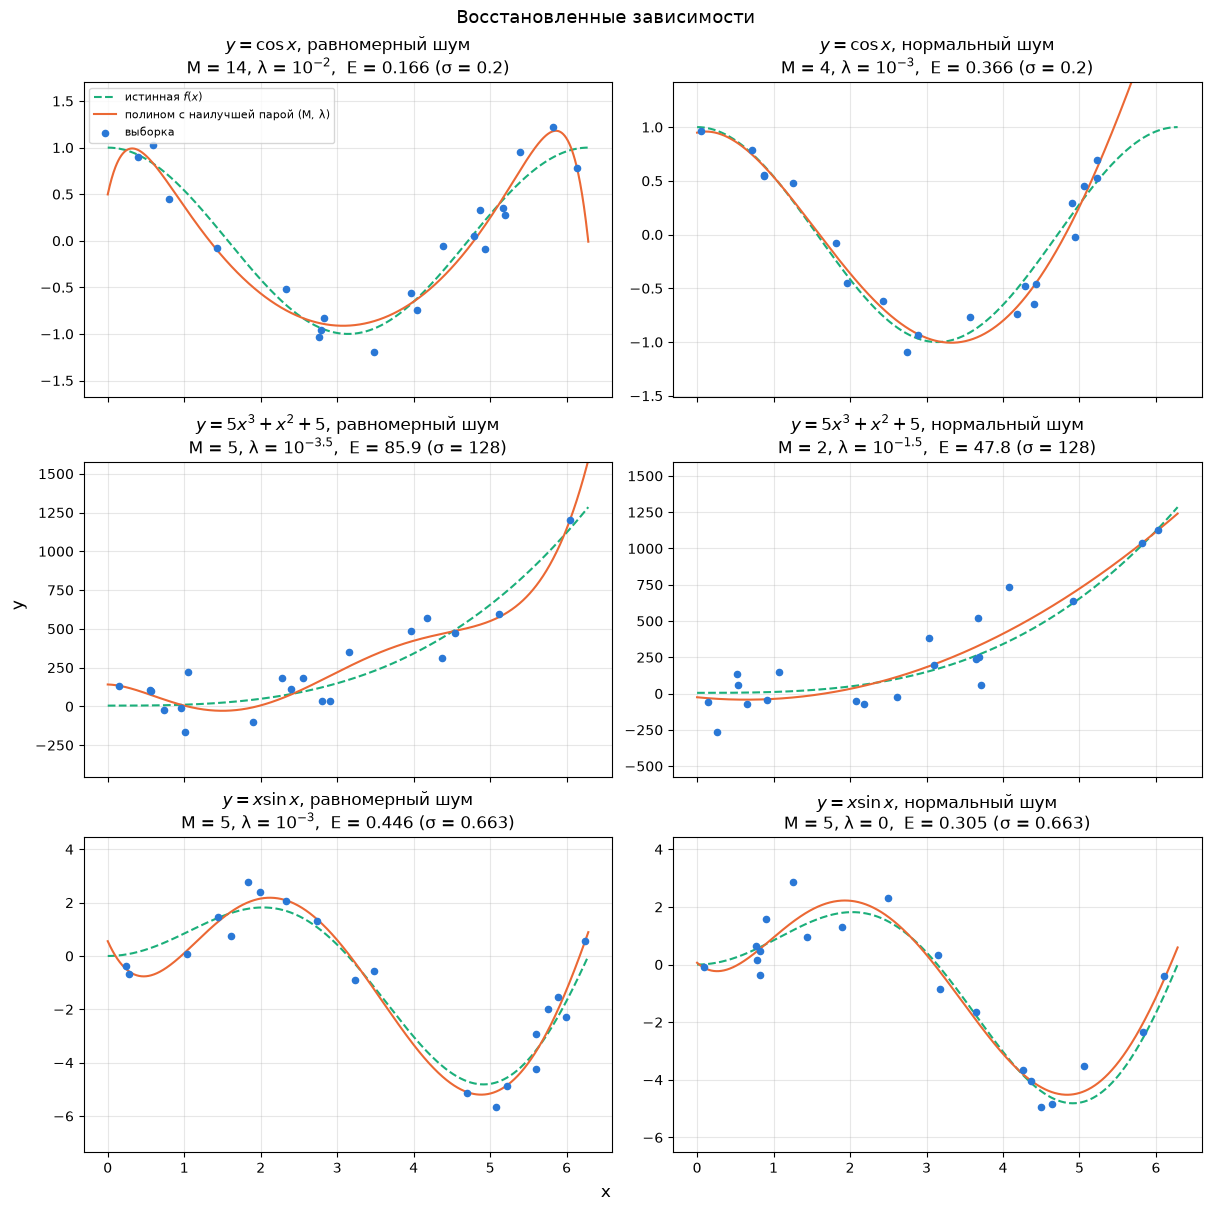

In [16]:
fig, axes = plt.subplots(
    len(functions),
    len(noise_types),
    figsize=(12, 12),
    sharex=True,
    layout="constrained",
)
for i, f_name in enumerate(functions):
    f_true = functions[f_name](x_grid)
    for j, noise_type in enumerate(noise_types):
        ax, res = axes[i, j], results[(f_name, noise_type)]
        x, t = res["x"], res["t"]
        M_cv, lam_cv = best_pairs[(f_name, noise_type)]

        w = fit_polynomial_reg(x, t, M_cv, lam_cv)  # итоговая модель — по всей выборке
        y_pred = predict(x_grid, w)
        E = np.sqrt(np.mean((y_pred - f_true) ** 2))  # проверка по истинной f

        y_lo, y_hi = min(f_true.min(), t.min()), max(f_true.max(), t.max())
        pad = 0.2 * (y_hi - y_lo)
        ax.plot(x_grid, f_true, "--", color="#1baf7a", lw=1.5, label="истинная $f(x)$")
        ax.plot(
            x_grid,
            y_pred,
            "-",
            color="#eb6834",
            lw=1.5,
            label="полином с наилучшей парой (M, λ)",
        )
        ax.scatter(x, t, s=20, color="#2a78d6", zorder=3, label="выборка")
        ax.set_ylim(y_lo - pad, y_hi + pad)
        lam_tex = "0" if lam_cv == 0 else f"$10^{{{np.log10(lam_cv):g}}}$"
        ax.set_title(
            f"{f_name}, {noise_names[noise_type]}\n"
            f"M = {M_cv}, λ = {lam_tex},  E = {E:.3g} (σ = {sigmas[f_name]:.3g})"
        )
        ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=8)
fig.supxlabel("x")
fig.supylabel("y")
fig.suptitle("Восстановленные зависимости", fontsize=13)
plt.show()